# Interpretação do Modelo (Explainable AI) — Predição de Carga Alta (EVCOMX)

Segue a **Aula 08 do bootcamp** (Interpretação de Modelos) e vem depois de
`verificacao_validacao/`: primeiro se valida, depois se interpreta.

**Modelo explicado: o oficial**, a média de 5 Gradient Boosting com 121 features (120 + o
resultado do cestão 1), **treinado no dev** (`selecao_algoritmos/modelo_dev.joblib`). As
explicações são feitas no **teste** (24/jun a 4/ago/26, 515 cestões, 75 cargas altas), que esse
modelo nunca viu. **Esta etapa não escolhe nada e não muda o modelo.**

> Antes, a explicação era da RF de 6 features (antigo plano A), com Shapley exato "na mão"
> (2⁶ = 64 combinações). Está em `historico_rf6/`.

**SHAP sem o pacote `shap`.** O pacote não pôde ser instalado no ambiente onde o projeto rodou.
`treeshap_hgb.py` implementa o mesmo TreeSHAP exato do `shap.TreeExplainer` (modo
"tree_path_dependent"), e o script **confere** que a conta fecha em todos os cestões e, se o
`shap` estiver instalado na sua máquina, que os valores batem com os dele.

| Passo da aula (slide 42) | Seção |
|---|---|
| 1. Valide antes de interpretar | `verificacao_validacao/` + seção 0 |
| 2. Quem recebe a explicação | README |
| Modelos transparentes (caixa de vidro) | 1 |
| 3. Importância global (permutação, SHAP; por grupo) | 2 |
| 4. Forma do efeito: PDP, ICE e casos impossíveis | 3 |
| 5. Explicar casos: SHAP e LIME | 4 e 5 |
| Contrafactuais (slide 35) | 6 |
| 6. Viés e casos estranhos | 7 |
| 7. Traduzir para o negócio | 8 |

**Rode antes** as etapas anteriores. Leva ~4 min.

In [1]:
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor, export_text

warnings.filterwarnings("ignore")
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "comum").is_dir())
sys.path.insert(0, str(RAIZ)); sys.path.insert(0, str(RAIZ / "interpretacao_modelos"))
from comum.protocolo import ARQ_COMPLETO, NOME_OFICIAL, carregar, ler_features, minutos
from comum.receita import Camada, camadas_da_base, recalcular, tabela_materiais
from treeshap_hgb import conferir_com_shap, shap_comite, shap_hgb

PASTA = RAIZ / "interpretacao_modelos"
(PASTA / "graficos").mkdir(exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e5e5e5", "grid.linewidth": 0.6, "axes.axisbelow": True})
AZUL, VERMELHO, CINZA, LARANJA, VERDE = "#2b6cb0", "#c0392b", "#7f8c8d", "#dd8a2e", "#4a8c4a"
CORES_G = {"histórico do forno": VERMELHO, "resultado do cestão 1": "#8e44ad", "gusa líquida": LARANJA,
           "ritmo do forno": "#b7950b", "regime recente (rel_)": VERDE, "massa, volume e densidade": AZUL,
           "materiais (prop_<código>)": "#5d6d7e", "ordem, ciclos e posição": "#1abc9c", "tempo e turno": CINZA,
           "contexto do cestão 1 (receita)": "#34495e"}

## 0. O modelo explicado é o que foi validado?

In [2]:
FEAT = ler_features(); F = FEAT["features_oficial"]; GRUPOS = FEAT["grupos"]
G_DE = {c: g for g, cols in GRUPOS.items() for c in cols}
D, DEV, TESTE = carregar(ARQ_COMPLETO)
PK = joblib.load(RAIZ / "selecao_algoritmos/modelo_dev.joblib")
MODELOS, LIM = PK["modelos"], PK["limiar_minutos_TP0"]
assert PK["features"] == F and PK["treinado_em"].startswith("treino + validação")


def chance(X):
    return np.mean([m.predict_proba(X[F])[:, 1] for m in MODELOS], axis=0)


p_te = chance(TESTE)
prev = pd.read_csv(RAIZ / "selecao_algoritmos/previsoes_dev_teste.csv")
ps = prev[(prev.modelo == NOME_OFICIAL) & (prev.parte == "teste")].set_index(["cd_corrida", "nu_carregamento"])
assert np.allclose(p_te, ps.loc[TESTE.set_index(["cd_corrida", "nu_carregamento"]).index, "p"].values, atol=1e-12)
alarme = p_te > LIM; y = TESTE.carga_alta.values.astype(bool)
print(f"Teste: PR-AUC {average_precision_score(y, p_te):.3f}, {alarme.sum()} alarmes (limiar {LIM:.3f}), "
      f"{minutos(y, TESTE.min_parada, alarme):.0f} min perdidos. Chances idênticas às da seleção.")

Teste: PR-AUC 0.567, 148 alarmes (limiar 0.178), 131 min perdidos. Chances idênticas às da seleção.


## 1. Modelos transparentes, a "caixa de vidro" (slides 16 a 20)

Com 121 colunas, nem uma logística é legível. Dois atalhos honestos:
- **logística com 10 features**, uma ou duas de cada grupo, padronizadas: os coeficientes dizem
  direção e tamanho, e a estabilidade em 300 reamostragens diz se dá para confiar no sinal;
- **árvore de 3 níveis que imita o oficial** (treinada para reproduzir as chances do oficial no
  dev): mostra a lógica principal em perguntas de sim/não. A **fidelidade** diz o quanto ela
  consegue imitar.

In [3]:
VIDRO = ["h_ewm2", "taxa_ca_ult10", "carga_alta_c1", "gusl_t", "prop_peso_pesado", "densidade_media",
         "peso_por_ciclo_t", "rendimento_medio", "eh_cestao_2", "intervalo_medio_min"]
Xd = DEV[VIDRO].fillna(DEV[VIDRO].median())
logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(Xd, DEV.carga_alta)
coef = pd.Series(logit[-1].coef_[0], index=VIDRO)
rng = np.random.default_rng(0); boots = []
pos_corrida = DEV.groupby("cd_corrida").indices
corridas = np.array(list(pos_corrida))
for _ in range(300):
    idx = np.concatenate([pos_corrida[c] for c in rng.choice(corridas, len(corridas))])
    boots.append(make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(Xd.iloc[idx], DEV.carga_alta.iloc[idx])[-1].coef_[0])
boots = np.array(boots)
coefs = pd.DataFrame({"coef por desvio-padrão": coef, "odds × por desvio-padrão": np.exp(coef),
                      "sinal trocado nas reamostragens (%)": 100 * (np.sign(boots) != np.sign(coef.values)).mean(0),
                      "grupo": [G_DE[c] for c in VIDRO]}).sort_values("coef por desvio-padrão", key=abs, ascending=False)
coefs.to_csv(PASTA / "coeficientes_logistica.csv")
p_vidro = logit.predict_proba(TESTE[VIDRO].fillna(DEV[VIDRO].median()))[:, 1]

p_dev = chance(DEV)
arv = DecisionTreeRegressor(max_depth=3, min_samples_leaf=40, random_state=0).fit(DEV[F].fillna(-1), p_dev)
p_arv = arv.predict(TESTE[F].fillna(-1))
fid_r2 = 1 - np.sum((p_arv - p_te) ** 2) / np.sum((p_te - p_te.mean()) ** 2)
fid_al = ((p_arv > LIM) == alarme).mean()
regras = export_text(arv, feature_names=F, decimals=2)
open(PASTA / "arvore_rasa_regras.txt", "w", encoding="utf-8").write(
    "Árvore de 3 níveis treinada para IMITAR as chances do modelo oficial no dev (value = chance média prevista)\n"
    f"Fidelidade no teste: R² {fid_r2:.2f}; mesma decisão de alarme em {fid_al:.0%} dos cestões\n\n" + regras)
print(regras)
print(f"Fidelidade da árvore no teste: R² {fid_r2:.2f}, mesma decisão de alarme em {fid_al:.0%}")
print(f"PR-AUC no teste: oficial {average_precision_score(y, p_te):.3f} | logística de 10 {average_precision_score(y, p_vidro):.3f} | "
      f"árvore imitadora {average_precision_score(y, p_arv):.3f}")
coefs.round(3)

|--- prop_peso_pesado <= 0.20
|   |--- h_ewm2 <= 0.48
|   |   |--- h_n_corridas_24h <= 9.50
|   |   |   |--- value: [0.29]
|   |   |--- h_n_corridas_24h >  9.50
|   |   |   |--- value: [0.09]
|   |--- h_ewm2 >  0.48
|   |   |--- carga_alta_c1 <= 0.50
|   |   |   |--- value: [0.70]
|   |   |--- carga_alta_c1 >  0.50
|   |   |   |--- value: [0.23]
|--- prop_peso_pesado >  0.20
|   |--- h_ewm2 <= 0.40
|   |   |--- densidade_media <= 0.90
|   |   |   |--- value: [0.10]
|   |   |--- densidade_media >  0.90
|   |   |   |--- value: [0.03]
|   |--- h_ewm2 >  0.40
|   |   |--- gusl_t <= 27.90
|   |   |   |--- value: [0.04]
|   |   |--- gusl_t >  27.90
|   |   |   |--- value: [0.26]

Fidelidade da árvore no teste: R² 0.62, mesma decisão de alarme em 83%
PR-AUC no teste: oficial 0.567 | logística de 10 0.523 | árvore imitadora 0.400


,coef por desvio-padrão,odds × por desvio-padrão,sinal trocado nas reamostragens (%),grupo
h_ewm2,0.861,2.366,0.000,histórico do forno
carga_alta_c1,-0.447,0.640,0.000,resultado do cestão 1
gusl_t,0.347,1.415,0.000,gusa líquida
densidade_media,-0.302,0.739,0.667,"massa, volume e densidade"
prop_peso_pesado,-0.277,0.758,2.000,"massa, volume e densidade"
rendimento_medio,-0.258,0.773,0.000,"massa, volume e densidade"
eh_cestao_2,0.221,1.247,0.333,contexto do cestão 1 (receita)
peso_por_ciclo_t,0.186,1.204,0.333,"ordem, ciclos e posição"
taxa_ca_ult10,-0.131,0.877,9.000,histórico do forno
intervalo_medio_min,0.021,1.021,33.000,tempo e turno


## 2. Importância global: por feature e por grupo (slides 22, 23 e 38)

O HGB não tem `feature_importances_` (a régua de impureza que enganava na RF antiga). Duas réguas:
- **permutação no teste**, por feature e **por grupo** (as cópias de uma mesma informação se
  cobrem quando embaralhadas uma a uma);
- **|SHAP| médio** (TreeSHAP, log-odds), por feature e somado por grupo.

SHAP: referência + Σ SHAP = saída do modelo em todos os 515 cestões (erro máx. 4.4e-15). Pacote shap: não instalado
                                |SHAP| médio do grupo  permutação do grupo  soma das permutações individuais  n features
histórico do forno                              0.622                0.312                             0.110          18
gusa líquida                                    0.385                0.010                             0.004           3
massa, volume e densidade                       0.373                0.046                             0.032          24
regime recente (rel_)                           0.262                0.045                             0.008          14
ritmo do forno                                  0.215                0.014                             0.003           4
tempo e turno                                   0.191                0.011                             0.001           7
resultado do cestão 1                

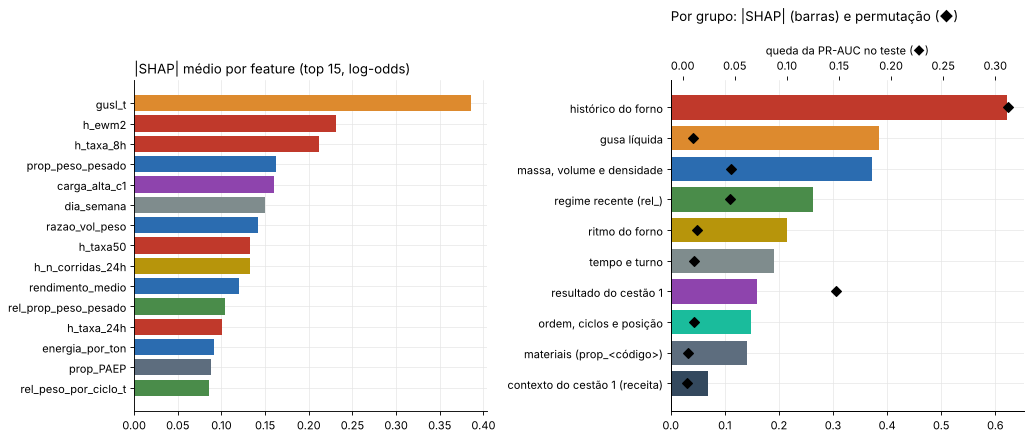

In [4]:
phi, ref = shap_comite(MODELOS, TESTE[F].values)
raw = np.mean([m.decision_function(TESTE[F]) for m in MODELOS], axis=0)
assert np.allclose(ref + phi.sum(1), raw, atol=1e-9), "a soma dos SHAP não fecha com o modelo"
dif_shap = conferir_com_shap(MODELOS[0], TESTE[F].values, shap_hgb(MODELOS[0], TESTE[F].values)[0])
print(f"SHAP: referência + Σ SHAP = saída do modelo em todos os {len(TESTE)} cestões (erro máx. "
      f"{np.abs(ref + phi.sum(1) - raw).max():.1e}). Pacote shap: "
      f"{'não instalado' if dif_shap is None else f'diferença máx. {dif_shap:.1e}'}")
PHI = pd.DataFrame(phi, columns=F)
PHI_G = pd.DataFrame({g: PHI[cols].sum(axis=1) for g, cols in GRUPOS.items()})

rng = np.random.default_rng(1)
base_pr = average_precision_score(y, p_te)
perm_f = {}
for c in F:
    q = []
    for _ in range(5):
        X = TESTE.copy(); X[c] = X[c].values[rng.permutation(len(X))]; q.append(base_pr - average_precision_score(y, chance(X)))
    perm_f[c] = np.mean(q)
perm_g = {}
for g, cols in GRUPOS.items():
    q = []
    for _ in range(10):
        X = TESTE.copy(); X[cols] = X[cols].values[rng.permutation(len(X))]; q.append(base_pr - average_precision_score(y, chance(X)))
    perm_g[g] = np.mean(q)
imp = pd.DataFrame({"grupo": [G_DE[c] for c in F], "|SHAP| médio": PHI.abs().mean().values,
                    "permutação no teste (queda PR-AUC)": pd.Series(perm_f)[F].values}, index=F)
imp["posição SHAP"] = imp["|SHAP| médio"].rank(ascending=False).astype(int)
imp["posição permutação"] = imp["permutação no teste (queda PR-AUC)"].rank(ascending=False).astype(int)
imp = imp.sort_values("|SHAP| médio", ascending=False)
imp.to_csv(PASTA / "importancia_global.csv")
imp_g = pd.DataFrame({"|SHAP| médio do grupo": PHI_G.abs().mean(), "permutação do grupo": pd.Series(perm_g),
                      "soma das permutações individuais": imp.groupby("grupo")["permutação no teste (queda PR-AUC)"].sum(),
                      "n features": pd.Series({g: len(c) for g, c in GRUPOS.items()})}).sort_values("|SHAP| médio do grupo", ascending=False)
imp_g.to_csv(PASTA / "importancia_por_grupo.csv")
print(imp_g.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 5.6))
t = imp.head(15)
axes[0].barh(t.index[::-1], t["|SHAP| médio"][::-1], color=[CORES_G[g] for g in t.grupo[::-1]])
axes[0].set_title("|SHAP| médio por feature (top 15, log-odds)", loc="left")
axes[1].barh(imp_g.index[::-1], imp_g["|SHAP| médio do grupo"][::-1], color=[CORES_G[g] for g in imp_g.index[::-1]], label="|SHAP| do grupo")
ax2 = axes[1].twiny()
ax2.plot(imp_g["permutação do grupo"][::-1], imp_g.index[::-1], "D", color="k", label="permutação do grupo (eixo de cima)")
ax2.set_xlabel("queda da PR-AUC no teste (◆)"); ax2.grid(False)
axes[1].set_title("Por grupo: |SHAP| (barras) e permutação (◆)\n", loc="left")
plt.tight_layout(); plt.savefig(PASTA / "graficos/01_importancia_global.png", dpi=130, bbox_inches="tight"); plt.show()

## 3. PDP, ICE e os "casos impossíveis" (slides 24 a 26 e 38)

O PDP muda **uma coluna** e deixa as outras 120 paradas. Com tantas colunas que andam juntas
(densidade, pesado, peso por ciclo, as `rel_`; as várias janelas do histórico), muitos pontos do
PDP são cestões que não existem. Medimos isso: um ponto é "impossível" quando a combinação com a
coluna mais ligada a ela cai numa célula da grade com menos de 3 cestões reais.

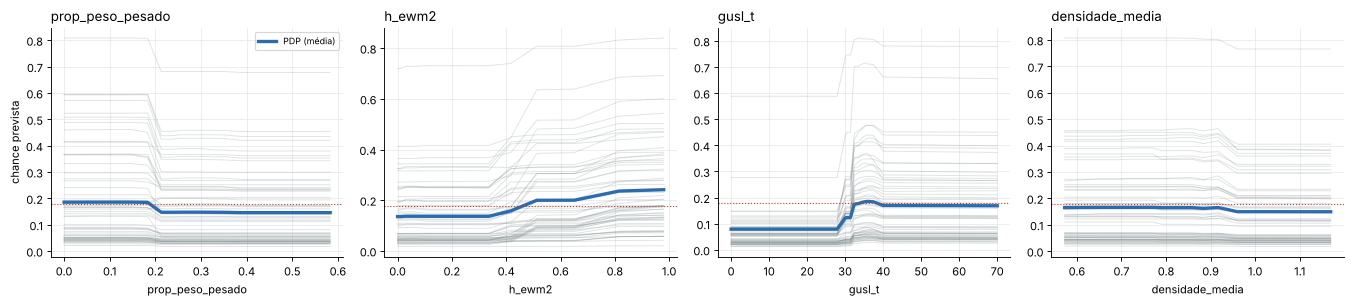

,feature,par com,% pontos do PDP em combinações quase inexistentes (< 3 cestões),sobe ou desce,chance no início,chance no fim,% das linhas ICE no mesmo sentido do PDP
0,prop_peso_pesado,densidade_media,24.233,desce,0.186,0.146,95.0
1,h_ewm2,taxa_ca_ult5,58.951,sobe,0.136,0.242,100.0
2,gusl_t,tem_gusl,2.563,sobe,0.079,0.169,100.0
3,densidade_media,prop_peso_pesado,27.353,desce,0.165,0.149,100.0


In [5]:
PDP = [("prop_peso_pesado", "densidade_media"), ("h_ewm2", "taxa_ca_ult5"), ("gusl_t", "tem_gusl"), ("densidade_media", "prop_peso_pesado")]
amostra = TESTE.sample(60, random_state=0)
fig, axes = plt.subplots(1, 4, figsize=(17, 3.9))
imposs = []
for ax, (c, par) in zip(axes, PDP):
    grade = np.quantile(D[c].dropna(), np.linspace(0.02, 0.98, 15))
    ice = np.array([chance(amostra.assign(**{c: v})) for v in grade]).T
    pdp = np.array([chance(TESTE.assign(**{c: v})).mean() for v in grade])
    for linha in ice:
        ax.plot(grade, linha, color=CINZA, alpha=0.25, lw=0.8)
    ax.plot(grade, pdp, color=AZUL, lw=3, label="PDP (média)")
    ax.axhline(LIM, color=VERMELHO, ls=":", lw=1); ax.set_xlabel(c); ax.set_title(c, loc="left")
    bx = np.quantile(D[c].dropna(), np.linspace(0, 1, 11)); by = np.quantile(D[par].dropna(), np.linspace(0, 1, 11))
    real = pd.crosstab(np.clip(np.searchsorted(bx, D[c], side="right") - 1, 0, 9), np.clip(np.searchsorted(by, D[par], side="right") - 1, 0, 9))
    cx = np.clip(np.searchsorted(bx, grade, side="right") - 1, 0, 9)
    cy = np.clip(np.searchsorted(by, TESTE[par].values, side="right") - 1, 0, 9)
    n_cel = np.array([[real.reindex(index=range(10), columns=range(10), fill_value=0).values[i, j] for j in cy] for i in cx])
    imposs.append({"feature": c, "par com": par, "% pontos do PDP em combinações quase inexistentes (< 3 cestões)": 100 * (n_cel < 3).mean(),
                   "sobe ou desce": "sobe" if pdp[-1] > pdp[0] else "desce", "chance no início": pdp[0], "chance no fim": pdp[-1],
                   "% das linhas ICE no mesmo sentido do PDP": 100 * (np.sign(ice[:, -1] - ice[:, 0]) == np.sign(pdp[-1] - pdp[0])).mean()})
axes[0].set_ylabel("chance prevista"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(PASTA / "graficos/02_pdp_ice.png", dpi=130, bbox_inches="tight"); plt.show()
imposs = pd.DataFrame(imposs); imposs.to_csv(PASTA / "pdp_casos_impossiveis.csv", index=False)
imposs.round(3)

## 4. SHAP (slides 28 a 31)

A referência é a saída média do modelo na escala dele (log-odds), que equivale a ~9% de chance
(a média das chances é ~16%: poucos cestões de risco alto puxam a média para cima). Cada valor diz quanto aquela coluna empurrou **este**
cestão para cima ou para baixo da referência, na escala do modelo (log-odds). Para falar em
**pontos de chance**, distribuímos a diferença "chance do cestão − chance de referência" entre os
grupos na proporção dos SHAP de cada grupo (a conta continua fechando).

Referência: 8.6%.
    cd_corrida  nu_carregamento  carga_alta  min_parada    h_ewm2  taxa_ca_ult5  carga_alta_c1  gusl_t  prop_peso_pesado  densidade_media    chance
466      O7174              2.0           1    8.933333  0.895195           0.8              0    36.3           0.00000         0.641046  0.858201
55       O6558              2.0           1    3.766667  0.000600           0.0              0    32.1           0.16888         0.767659  0.024316


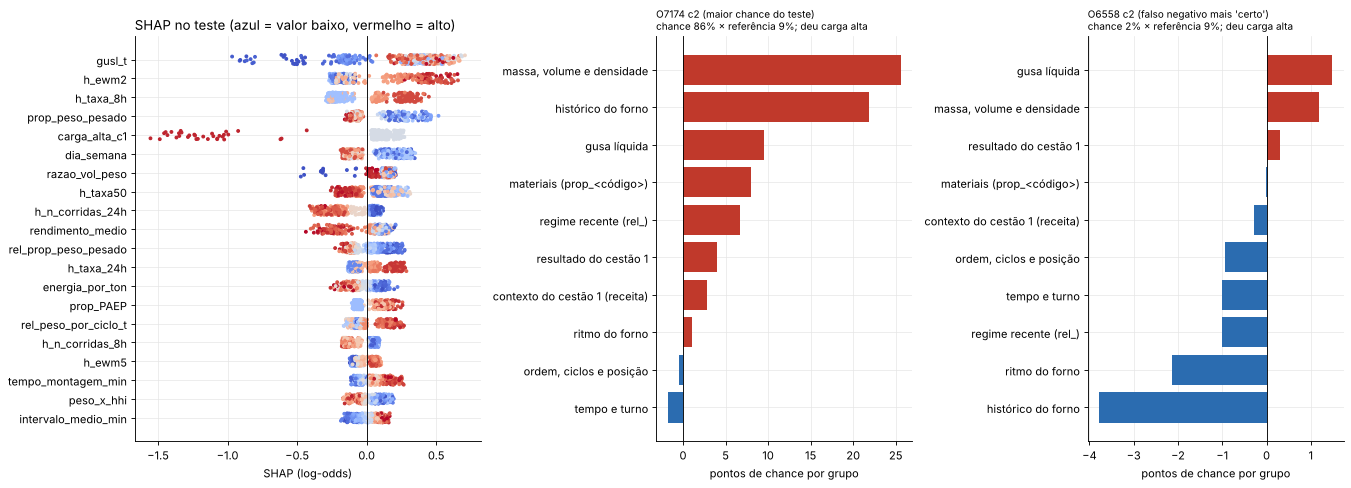

,maior chance,falso negativo
"massa, volume e densidade",25.6,1.2
"ordem, ciclos e posição",-0.5,-0.9
materiais (prop_<código>),7.9,-0.0
tempo e turno,-1.8,-1.0
contexto do cestão 1 (receita),2.8,-0.3
histórico do forno,21.8,-3.8
gusa líquida,9.5,1.5
ritmo do forno,1.1,-2.1
regime recente (rel_),6.7,-1.0
resultado do cestão 1,4.1,0.3


In [6]:
p_ref = 1 / (1 + np.exp(-ref))


def pontos_por_grupo(i):
    s = PHI_G.iloc[i]
    tot = s.sum()
    return s / tot * (p_te[i] - p_ref) if abs(tot) > 1e-12 else s * 0


top20 = imp.index[:20]
fig, axes = plt.subplots(1, 3, figsize=(17, 6.2), gridspec_kw={"width_ratios": [1.35, 1, 1]})
for k, c in enumerate(top20[::-1]):
    v = TESTE[c].values.astype(float); r_ = (pd.Series(v).rank(pct=True)).values
    axes[0].scatter(PHI[c], np.full(len(v), k) + rng.uniform(-0.25, 0.25, len(v)), c=r_, cmap="coolwarm", s=6, vmin=0, vmax=1)
axes[0].set_yticks(range(20), top20[::-1]); axes[0].axvline(0, color="k", lw=0.8)
axes[0].set_title("SHAP no teste (azul = valor baixo, vermelho = alto)", loc="left"); axes[0].set_xlabel("SHAP (log-odds)")
i_max = int(np.argmax(p_te))
fn = np.where(y & ~alarme)[0]; i_fn = int(fn[np.argmin(p_te[fn])]) if len(fn) else int(np.argmin(p_te))
for ax, i, tit in [(axes[1], i_max, "maior chance do teste"), (axes[2], i_fn, "falso negativo mais 'certo'")]:
    pg = pontos_por_grupo(i).sort_values()
    ax.barh(pg.index, 100 * pg.values, color=[VERMELHO if v > 0 else AZUL for v in pg.values]); ax.axvline(0, color="k", lw=0.8)
    r = TESTE.iloc[i]
    ax.set_title(f"{r.cd_corrida} c{int(r.nu_carregamento)} ({tit})\nchance {p_te[i]:.0%} × referência {p_ref:.0%}; "
                 f"{'deu' if y[i] else 'não deu'} carga alta", loc="left", fontsize=9)
    ax.set_xlabel("pontos de chance por grupo")
plt.tight_layout(); plt.savefig(PASTA / "graficos/03_shap_visao_geral_e_dois_cestoes.png", dpi=130, bbox_inches="tight"); plt.show()
dois = pd.DataFrame({"maior chance": 100 * pontos_por_grupo(i_max), "falso negativo": 100 * pontos_por_grupo(i_fn)})
print(f"Referência: {p_ref:.1%}.")
print(TESTE.iloc[[i_max, i_fn]][["cd_corrida", "nu_carregamento", "carga_alta", "min_parada", "h_ewm2", "taxa_ca_ult5",
                                  "carga_alta_c1", "gusl_t", "prop_peso_pesado", "densidade_media"]].assign(chance=p_te[[i_max, i_fn]]).to_string())
dois.round(1)

## 5. LIME (slides 32 a 34)

No mesmo falso negativo. Com 121 colunas, perturbar coluna a coluna cria cestões impossíveis;
por isso o LIME aqui trabalha **por grupo**: cada amostra liga ou desliga grupos (ligado = valores
do cestão; desligado = valores de outro cestão do dev, sorteado), pondera pela proximidade e
ajusta uma regressão linear. 20 execuções com sementes diferentes medem a estabilidade.

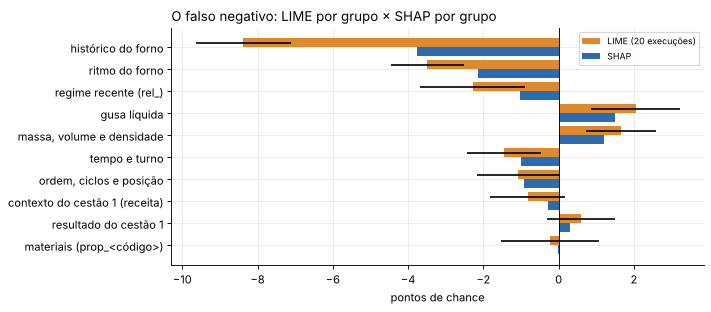

,LIME média (pontos),LIME dp,troca de sinal (%),SHAP do mesmo cestão (pontos)
histórico do forno,-8.38,1.27,0.0,-3.78
ritmo do forno,-3.49,0.97,0.0,-2.14
regime recente (rel_),-2.28,1.40,10.0,-1.02
gusa líquida,2.04,1.17,5.0,1.49
"massa, volume e densidade",1.66,0.93,0.0,1.20
tempo e turno,-1.45,0.97,5.0,-1.01
"ordem, ciclos e posição",-1.08,1.10,25.0,-0.93
contexto do cestão 1 (receita),-0.82,0.99,20.0,-0.28
resultado do cestão 1,0.60,0.90,30.0,0.30
materiais (prop_<código>),-0.22,1.30,35.0,-0.01


In [7]:
GL = list(GRUPOS)
x0 = TESTE.iloc[[i_fn]]
fundo = DEV.sample(400, random_state=0).reset_index(drop=True)


def lime(seed, n=400):
    r = np.random.default_rng(seed)
    Z = r.integers(0, 2, (n, len(GL))); Z[0] = 1
    X = pd.concat([x0] * n, ignore_index=True)
    outros = fundo.iloc[r.integers(0, len(fundo), n)].reset_index(drop=True)
    for j, g in enumerate(GL):
        off = Z[:, j] == 0
        X.loc[off, GRUPOS[g]] = outros.loc[off, GRUPOS[g]].values
    pz = chance(X)
    w = np.exp(-((len(GL) - Z.sum(1)) / len(GL)) ** 2 / 0.25)
    A = np.c_[np.ones(n), Z]
    beta = np.linalg.solve(A.T @ (A * w[:, None]) + 1e-3 * np.eye(A.shape[1]), A.T @ (w * pz))
    return beta[1:]


lim_runs = np.array([lime(s) for s in range(20)])
lime_df = pd.DataFrame({"LIME média (pontos)": 100 * lim_runs.mean(0), "LIME dp": 100 * lim_runs.std(0),
                        "troca de sinal (%)": 100 * (np.sign(lim_runs) != np.sign(lim_runs.mean(0))).mean(0),
                        "SHAP do mesmo cestão (pontos)": 100 * pontos_por_grupo(i_fn)[GL].values}, index=GL)
lime_df = lime_df.sort_values("LIME média (pontos)", key=abs, ascending=False)
lime_df.to_csv(PASTA / "lime_estabilidade.csv")
fig, ax = plt.subplots(figsize=(9, 4))
yy = np.arange(len(lime_df))
ax.barh(yy - 0.2, lime_df["LIME média (pontos)"], 0.4, xerr=lime_df["LIME dp"], color=LARANJA, label="LIME (20 execuções)")
ax.barh(yy + 0.2, lime_df["SHAP do mesmo cestão (pontos)"], 0.4, color=AZUL, label="SHAP")
ax.set_yticks(yy, lime_df.index); ax.invert_yaxis(); ax.axvline(0, color="k", lw=0.8); ax.legend(fontsize=8)
ax.set_xlabel("pontos de chance"); ax.set_title("O falso negativo: LIME por grupo × SHAP por grupo", loc="left")
plt.tight_layout(); plt.savefig(PASTA / "graficos/04_lime_estabilidade.png", dpi=130, bbox_inches="tight"); plt.show()
lime_df.round(2)

## 6. Contrafactuais: o que mudaria o alarme? (slide 35)

Para cada cestão alarmado no teste: **quantas toneladas de leve trocadas por pesado** (gusa sólida,
GUSS, colocada no topo) tirariam o cestão do alarme? A receita é recalculada inteira, como no app:
densidade, proporções, ciclos, posição e `rel_` mudam juntas (versão **coerente**). O histórico, a
gusa líquida e o resultado do cestão 1 não se mudam na montagem.

Versão **ingênua**, para comparar: mexer só em `prop_peso_pesado`, com o resto parado.

In [8]:
base = pd.read_csv(RAIZ / "EDA/base.csv", dtype={"cd_codigo_material": str})
mats = tabela_materiais(base, F)
orig = camadas_da_base(base, TESTE.cd_corrida)
idx_al = np.where(alarme)[0]


def trocar(camadas, t):
    cams = [list(c) for c in camadas]; resto = t
    for c in cams:
        if resto <= 0:
            break
        if mats.loc[c[0], "classe"] == "Leve" and c[1] > 2.0:
            tira = min(resto, c[1] - 2.0); c[1] -= tira; resto -= tira
    feito = t - resto
    return [Camada(a, b) for a, b in cams] + ([Camada("GUSS", feito)] if feito > 0 else []), feito


cf = {i: None for i in idx_al}
feitos = {}
for t in range(1, 16):
    pend = [i for i in idx_al if cf[i] is None]
    if not pend:
        break
    sub = TESTE.iloc[pend]
    novas, ok_t = {}, {}
    for i in pend:
        k = (TESTE.cd_corrida.iloc[i], TESTE.nu_carregamento.iloc[i])
        novas[k], ok_t[i] = trocar(orig[k], float(t))
    # o outro cestão da corrida fica igual (precisa estar na tabela por causa das features do cestão 1)
    outros = TESTE[TESTE.cd_corrida.isin(sub.cd_corrida) & ~TESTE.index.isin(sub.index)]
    tab = pd.concat([sub, outros])
    X = recalcular(tab, novas, mats, F).set_index(["cd_corrida", "nu_carregamento"]).loc[list(novas)].reset_index()
    pn = chance(X)
    for j, i in enumerate(pend):
        if pn[j] <= LIM and ok_t[i] >= t - 1e-9:
            cf[i] = t
ing = {}
for dp in np.arange(0.02, 0.62, 0.02):
    pend = [i for i in idx_al if i not in ing]
    X = TESTE.iloc[pend].copy(); X["prop_peso_pesado"] = np.minimum(X.prop_peso_pesado + dp, 1)
    for i, pn in zip(pend, chance(X)):
        if pn <= LIM:
            ing[i] = dp
cfd = pd.DataFrame({"cd_corrida": TESTE.cd_corrida.values[idx_al], "nu_carregamento": TESTE.nu_carregamento.values[idx_al],
                    "chance": p_te[idx_al], "carga_alta": y[idx_al].astype(int),
                    "histórico (5 corridas)": TESTE.taxa_ca_ult5.values[idx_al], "cestão 1 deu": TESTE.carga_alta_c1.values[idx_al],
                    "t de leve → pesado para sair do alarme (coerente)": [cf[i] for i in idx_al],
                    "+ p.p. de pesado (ingênuo)": [100 * ing[i] if i in ing else np.nan for i in idx_al]})
cfd.to_csv(PASTA / "contrafactuais_teste.csv", index=False)
COL_T = "t de leve → pesado para sair do alarme (coerente)"
cfd["forno"] = np.where(cfd["histórico (5 corridas)"] >= 0.4, "agitado (≥ 2 nas últimas 5)", "calmo")
res_cf = cfd.groupby("forno").agg(alarmes=("chance", "size"),
                                  sai_com_ate_15t=("t de leve → pesado para sair do alarme (coerente)", lambda s: 100 * s.notna().mean()),
                                  toneladas_mediana=("t de leve → pesado para sair do alarme (coerente)", "median"))
res_cf.loc["todos"] = [len(cfd), 100 * cfd[COL_T].notna().mean(), cfd[COL_T].median()]
res_cf["ingênuo: + p.p. de pesado (mediana)"] = list(cfd.groupby("forno")["+ p.p. de pesado (ingênuo)"].median()) + [cfd["+ p.p. de pesado (ingênuo)"].median()]
res_cf.to_csv(PASTA / "contrafactuais_resumo.csv")
res_cf.round(1)

,alarmes,sai_com_ate_15t,toneladas_mediana,ingênuo: + p.p. de pesado (mediana)
forno,,,,
agitado (≥ 2 nas últimas 5),115.0,47.8,4.0,10.0
calmo,33.0,81.8,1.0,14.0
todos,148.0,55.4,3.0,12.0


## 7. Viés e casos estranhos (slide 39)

Não há pessoas sendo decididas, então não há grupo protegido. O equivalente: o modelo trata igual
situações iguais? Olhamos **cestão 1 × cestão 2** e **o que puxa cada alarme**.

In [9]:
vies = []
for k in [1, 2]:
    m_ = TESTE.nu_carregamento.values == k
    vies.append({"cestão": k, "cestões": int(m_.sum()), "taxa real": y[m_].mean(), "alarmes (%)": 100 * alarme[m_].mean(),
                 "recall": (alarme & y & m_).sum() / max((y & m_).sum(), 1), "precisão": (alarme & y & m_).sum() / max((alarme & m_).sum(), 1),
                 "|SHAP| médio da receita": PHI_G.loc[m_, [g for g in GL if g in ("massa, volume e densidade", "materiais (prop_<código>)",
                                                                           "ordem, ciclos e posição", "regime recente (rel_)")]].sum(1).abs().mean(),
                 "|SHAP| médio do histórico": PHI_G.loc[m_, "histórico do forno"].abs().mean()})
vies = pd.DataFrame(vies); vies.to_csv(PASTA / "vies_cestao1_cestao2.csv", index=False)
RECEITA = ["massa, volume e densidade", "materiais (prop_<código>)", "ordem, ciclos e posição", "regime recente (rel_)",
           "contexto do cestão 1 (receita)", "tempo e turno"]
puxa = pd.DataFrame({"histórico do forno": PHI_G["histórico do forno"], "receita do cestão": PHI_G[RECEITA].sum(1),
                     "gusa líquida": PHI_G["gusa líquida"], "resultado do cestão 1": PHI_G["resultado do cestão 1"],
                     "ritmo do forno": PHI_G["ritmo do forno"]})
motivo = puxa[alarme].idxmax(axis=1)
mot = pd.DataFrame({"alarmes": motivo.value_counts(), "precisão": pd.Series({m_: y[alarme][motivo.values == m_].mean() for m_ in motivo.unique()})})
mot["% dos alarmes"] = 100 * mot.alarmes / mot.alarmes.sum()
mot.to_csv(PASTA / "motivo_dos_alarmes.csv")
print(vies.round(3).to_string(index=False)); print(); print(mot.round(3).to_string())

 cestão  cestões  taxa real  alarmes (%)  recall  precisão  |SHAP| médio da receita  |SHAP| médio do histórico
      1      270      0.141       27.407   0.789     0.405                    0.406                      0.576
      2      245      0.151       30.204   0.730     0.365                    0.662                      0.672

                    alarmes  precisão  % dos alarmes
gusa líquida             15     0.267         10.135
histórico do forno       63     0.413         42.568
receita do cestão        70     0.386         47.297


## 8. Traduzir para o negócio (slide 40)

Cada alarme (e cada carga alta perdida) do teste ganha uma explicação em 3 frases, com os dois
grupos que mais subiram a chance e o que mais segurou, em linguagem do pátio.

In [10]:
FRASE = {
    "histórico do forno": lambda r: (lambda k: f"forno com carga alta recente ({k} das últimas 5 corridas)" if k >= 2
                                     else f"forno calmo ({k} carga alta nas últimas 5 corridas)")(
        int(round(5 * (r.taxa_ca_ult5 if pd.notna(r.taxa_ca_ult5) else 0)))),
    "resultado do cestão 1": lambda r: "o cestão 1 desta corrida deu carga alta" if r.carga_alta_c1 == 1 else "o cestão 1 desta corrida não deu carga alta",
    "gusa líquida": lambda r: f"{r.gusl_t:.0f} t de gusa líquida na corrida" if r.gusl_t > 0 else "corrida sem gusa líquida",
    "massa, volume e densidade": lambda r: f"cestão {'fofo' if r.densidade_media < 0.8 else 'denso'} ({r.densidade_media:.2f} t/m³, {r.prop_peso_pesado:.0%} de pesado)",
    "materiais (prop_<código>)": lambda r: f"mistura de materiais ({int(r.num_materiais)} materiais)",
    "ordem, ciclos e posição": lambda r: f"montagem com {int(r.n_ciclos)} ciclos ({r.peso_por_ciclo_t:.0f} t por ciclo)",
    "regime recente (rel_)": lambda r: f"cestão {'mais fofo' if r.rel_densidade_media < 0 else 'mais denso'} que os dos últimos dias",
    "ritmo do forno": lambda r: f"{r.gap_corrida_min:.0f} min desde a corrida anterior",
    "tempo e turno": lambda r: f"montagem de {r.tempo_montagem_min:.0f} min",
    "contexto do cestão 1 (receita)": lambda r: "o que já entrou no cestão 1",
}
linhas = []
for i in np.where(alarme | y)[0]:
    r = TESTE.iloc[i]; pg = pontos_por_grupo(i)
    sobe = [g for g in pg.sort_values(ascending=False).index if pg[g] > 0.01][:2]
    segura = [g for g in pg.sort_values().index if pg[g] < -0.01][:1]
    nivel = "alto" if p_te[i] > 0.4 else ("médio" if p_te[i] > LIM else "baixo")
    txt = (f"Risco {nivel}: o modelo deu {100 * p_te[i]:.0f} pontos de chance, contra {100 * p_ref:.0f} do cestão de referência. "
           + (f"O que mais aumentou o risco: {' e '.join(FRASE[g](r) for g in sobe)}. " if sobe else "Nenhuma característica aumentou muito o risco. ")
           + (f"O que segurou o risco: {FRASE[segura[0]](r)}." if segura else "Nada segurou o risco."))
    linhas.append({"cd_corrida": r.cd_corrida, "cestão": int(r.nu_carregamento), "chance": p_te[i], "alarme": bool(alarme[i]),
                   "deu carga alta": bool(y[i]), "explicação": txt, **{f"pontos: {g}": 100 * pg[g] for g in GL}})
expl = pd.DataFrame(linhas); expl.to_csv(PASTA / "explicacoes_alarmes_teste.csv", index=False)
for i in [i_max, i_fn]:
    e = expl[(expl.cd_corrida == TESTE.cd_corrida.iloc[i]) & (expl["cestão"] == int(TESTE.nu_carregamento.iloc[i]))].iloc[0]
    print(f"{e.cd_corrida} c{e['cestão']} ({'alarme' if e.alarme else 'sem alarme'}, {'deu' if e['deu carga alta'] else 'não deu'} carga alta):\n  {e['explicação']}\n")
print(f"{len(expl)} cestões explicados ({alarme.sum()} alarmes e {(y & ~alarme).sum()} cargas altas perdidas).")

O7174 c2 (alarme, deu carga alta):
  Risco alto: o modelo deu 86 pontos de chance, contra 9 do cestão de referência. O que mais aumentou o risco: cestão fofo (0.64 t/m³, 0% de pesado) e forno com carga alta recente (4 das últimas 5 corridas). O que segurou o risco: montagem de 12 min.

O6558 c2 (sem alarme, deu carga alta):
  Risco baixo: o modelo deu 2 pontos de chance, contra 9 do cestão de referência. O que mais aumentou o risco: 32 t de gusa líquida na corrida e cestão fofo (0.77 t/m³, 17% de pesado). O que segurou o risco: forno calmo (0 carga alta nas últimas 5 corridas).

166 cestões explicados (148 alarmes e 18 cargas altas perdidas).
